# 06 · Ramadan 1443: how the daily rhythm and place visits change

Output 2 (applied analysis). Ramadan 1443 started on 3 Apr 2022 for the government and on 2 Apr for Muhammadiyah (`data/raw/external/calendar_2021_2022.csv`). The study period ends on 30 Apr, so it covers almost the whole month.

Comparison windows (`src/applied.py`, `ramadan_windows`): the first 21 days of Ramadan (3–23 Apr) against the 21 days before (12 Mar–1 Apr). 2 Apr is left out because only part of the population had started fasting. Holidays inside the windows (Good Friday, 15 Apr) are left out. Both windows lie in panel segment S3, so there is no panel break between them; the panel still shrinks within S3, which is why every JogjaPulse measure here is a share, not a count.

Notebook 02 showed that the two sources agree weakly to moderately on one leisure proxy (Gunungkidul share vs Google parks), so Google is used here as a second view, not as a check of each number. Google also has 2021, which lets us see whether a change repeats in Ramadan 1442 (13 Apr 2021, `config.RAMADAN_2021_START`) or is just the season.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import (CALENDAR_CSV, FIGURES as FIG, GOOGLE_CATEGORIES, KAB_ORDER, PROCESSED, RAW_EXT,
                    RAMADAN_2021_START)
from applied import complete_days, pooled_profile, ramadan_windows

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 160, "display.max_columns", 30)
JP_COL, G_COL = "#0F766E", "#C2410C"   # slide colours (presentation/slides_plan.md)
FIGSIZE = (12.8, 7.2)                   # 1920 x 1080 at 150 dpi
KAB_COL = dict(zip(KAB_ORDER, sns.color_palette("Set2", len(KAB_ORDER))))

daily = pd.read_parquet(PROCESSED / "daily_diy.parquet").set_index("date")
hourly = pd.read_parquet(PROCESSED / "hourly_kapanewon.parquet",
                         columns=["kab_kota", "kapanewon_code", "kapanewon", "date", "hour",
                                  "n_maids", "share_of_own_day"])
hourly["date"] = hourly["date"].astype("datetime64[ns]")
cal = pd.read_csv(CALENDAR_CSV, parse_dates=["date"])
names = hourly.drop_duplicates("kapanewon_code").set_index("kapanewon_code")[["kab_kota", "kapanewon"]]

START = cal.loc[cal.name.str.contains("government"), "date"].iloc[0]
START_MUH = cal.loc[cal.name.str.contains("Muhammadiyah"), "date"].iloc[0]
before, during = ramadan_windows(START)
before = before[~daily.is_holiday.reindex(before).to_numpy()]
during = during[~daily.is_holiday.reindex(during).to_numpy()]
assert (daily.panel_segment.reindex(before.union(during)) == "S3 16 Feb-Apr").all()
print(f"Ramadan start: {START.date()} (government), {START_MUH.date()} (Muhammadiyah)")
print(f"Before: {before[0].date()} to {before[-1].date()}, {len(before)} days | "
      f"During: {during[0].date()} to {during[-1].date()}, {len(during)} days")

def savefig(fig, name):
    fig.savefig(FIG / f"ramadan_{name}.png")

Ramadan start: 2022-04-03 (government), 2022-04-02 (Muhammadiyah)
Before: 2022-03-12 to 2022-04-01, 21 days | During: 2022-04-03 to 2022-04-23, 20 days


## 1. DIY hourly profile before and during Ramadan

All kapanewon pooled: each hour's share of the day's device-hours, averaged over the days in each window.

In [2]:
prof = pooled_profile(hourly)
p_before, p_during = prof.loc[before].mean(), prof.loc[during].mean()
diff = p_during - p_before
tbl = pd.DataFrame({"before (%)": p_before, "Ramadan (%)": p_during, "change (pp)": diff}).round(2)
display(tbl.T)
blocks = {"00-02": [0, 1, 2], "03-04": [3, 4], "05-08": [5, 6, 7, 8], "09-15": list(range(9, 16)),
          "16-17": [16, 17], "18-19": [18, 19], "20-23": [20, 21, 22, 23]}
block_tbl = pd.DataFrame({b: [p_before[h].sum(), p_during[h].sum()] for b, h in blocks.items()},
                         index=["before (%)", "Ramadan (%)"]).T
block_tbl["change (pp)"] = block_tbl["Ramadan (%)"] - block_tbl["before (%)"]
display(block_tbl.round(2))

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
before (%),2.61,5.25,3.46,1.95,1.80,3.11,4.05,4.04,4.55,4.63,4.61,4.92,5.09,4.84,4.77,4.65,4.69,4.97,5.25,5.15,5.01,4.36,3.67,2.59
Ramadan (%),1.98,1.64,2.33,3.77,4.32,3.05,3.34,3.61,4.42,4.77,4.96,5.17,5.24,5.03,5.12,4.81,4.90,4.85,5.50,4.59,5.19,4.70,3.92,2.80
change (pp),-0.63,-3.61,-1.13,1.82,2.52,-0.06,-0.71,-0.44,-0.13,0.15,0.35,0.25,0.15,0.20,0.35,0.17,0.21,-0.12,0.25,-0.55,0.18,0.33,0.25,0.22


,before (%),Ramadan (%),change (pp)
00-02,11.32,5.95,-5.37
03-04,3.75,8.09,4.34
05-08,15.75,14.41,-1.34
09-15,33.50,35.11,1.61
16-17,9.66,9.75,0.08
18-19,10.39,10.10,-0.30
20-23,15.62,16.60,0.98


## 2. When did the change start?

Daily share of the day's device-hours in two hour blocks: 03:00–04:59 (the block that rises most) and 00:00–02:59 (the block that falls most). A change that comes from Ramadan should step at 2–3 Apr; a change from the panel would drift.

            03-04  00-02
date                    
2022-03-28    5.2   15.0
2022-03-29    5.6   13.2
2022-03-30    3.9   14.4
2022-03-31    4.5   15.0
2022-04-01    3.9   10.4
2022-04-02    6.8    6.8
2022-04-03   16.2    9.7
2022-04-04    9.1    5.4
2022-04-05   10.3    7.7
2022-04-06    5.6    3.6
2022-04-07    7.5    5.6
2022-04-08    9.2    8.3
03-04 share: highest day before Ramadan 5.6%; Ramadan days above that: 19 of 20


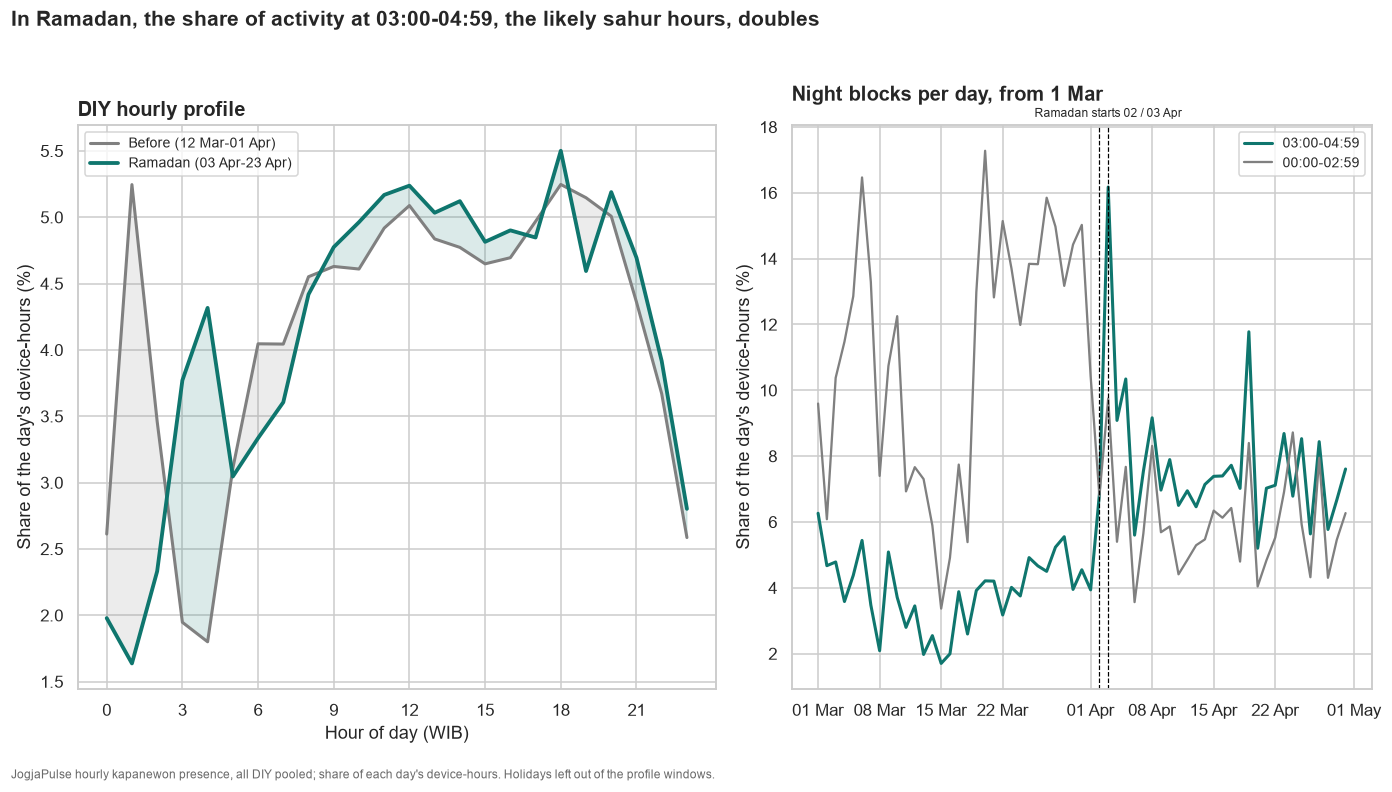

In [3]:
series = pd.DataFrame({"03-04": prof[[3, 4]].sum(axis=1), "00-02": prof[[0, 1, 2]].sum(axis=1)})
win = series.loc["2022-03-01":]
print(win.loc["2022-03-28":"2022-04-08"].round(1).to_string())
pre_max = series.loc[before, "03-04"].max()
n_above = (series.loc[during, "03-04"] > pre_max).sum()
print(f"03-04 share: highest day before Ramadan {pre_max:.1f}%; Ramadan days above that: {n_above} of {len(during)}")

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
x = np.arange(24)
ax.plot(x, p_before, color="grey", lw=2, label=f"Before ({before[0]:%d %b}-{before[-1]:%d %b})")
ax.plot(x, p_during, color=JP_COL, lw=2.5, label=f"Ramadan ({during[0]:%d %b}-{during[-1]:%d %b})")
ax.fill_between(x, p_before, p_during, where=p_during > p_before, color=JP_COL, alpha=.15, interpolate=True)
ax.fill_between(x, p_before, p_during, where=p_during < p_before, color="grey", alpha=.15, interpolate=True)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (WIB)")
ax.set_ylabel("Share of the day's device-hours (%)")
ax.set_title("DIY hourly profile", loc="left")
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(win.index, win["03-04"], color=JP_COL, lw=2, label="03:00-04:59")
ax.plot(win.index, win["00-02"], color="grey", lw=1.5, label="00:00-02:59")
for d in (START_MUH, START):
    ax.axvline(d, color="black", lw=.8, ls="--")
ax.text(START, 1.01, f"Ramadan starts {START_MUH:%d} / {START:%d %b}", fontsize=8,
        transform=ax.get_xaxis_transform(), ha="center", va="bottom")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Share of the day's device-hours (%)")
ax.set_title("Night blocks per day, from 1 Mar", loc="left", pad=16)
ax.legend(fontsize=9)
fig.suptitle("In Ramadan, the share of activity at 03:00-04:59, the likely sahur hours, doubles",
             x=.01, ha="left", fontweight="bold", fontsize=14)
fig.text(.01, .01, "JogjaPulse hourly kapanewon presence, all DIY pooled; share of each day's device-hours. "
         "Holidays left out of the profile windows.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, .96))
savefig(fig, "hourly_profile")

### 2b. Who drove the 00-02 block before Ramadan?

Before Ramadan, a few kapanewon had a peak around 01:00 (notebook 03 cluster 1). If the 00-02 drop comes only from them, it is a local change, not a DIY-wide one.

In [4]:
h_before = hourly[hourly.date.isin(before)]
h_during = hourly[hourly.date.isin(during)]
early = lambda h: h[h.hour <= 2].groupby("kapanewon_code").n_maids.sum()
contrib = (early(h_before) / early(h_before).sum() * 100).sort_values(ascending=False)
print("Share of DIY 00-02 device-hours before Ramadan, top 5 kapanewon (%):")
print(contrib.head(5).round(1).rename(names.kapanewon).to_string())
top4 = contrib.index[:4]
rest = hourly[~hourly.kapanewon_code.isin(top4)]
prof_rest = pooled_profile(rest)
d_rest = prof_rest.loc[during].mean() - prof_rest.loc[before].mean()
print("\nChange without those 4 kapanewon (pp):",
      {b: round(d_rest[h].sum(), 2) for b, h in blocks.items()})

Share of DIY 00-02 device-hours before Ramadan, top 5 kapanewon (%):
kapanewon_code
GONDOMANAN    44.6
SLEMAN        16.3
TEGALREJO      4.9
BANTUL         3.9
DEPOK          3.5

Change without those 4 kapanewon (pp): {'00-02': np.float64(0.47), '03-04': np.float64(4.68), '05-08': np.float64(-2.09), '09-15': np.float64(-0.84), '16-17': np.float64(-0.92), '18-19': np.float64(-1.01), '20-23': np.float64(-0.28)}


## 3. By kabupaten and by kapanewon

Kabupaten profiles pool their kapanewon. For single kapanewon only complete 24-hour days are used (the night hours are where suppression hits), and a kapanewon needs at least 5 complete days in each window.

In [5]:
kprof = pooled_profile(hourly, group="kab_kota")
k_before = kprof[kprof.index.get_level_values("date").isin(before)].groupby(level="kab_kota").mean()
k_during = kprof[kprof.index.get_level_values("date").isin(during)].groupby(level="kab_kota").mean()
kab_tbl = pd.DataFrame({b: (k_during[h].sum(axis=1) - k_before[h].sum(axis=1)) for b, h in blocks.items()}
                       ).reindex(KAB_ORDER).round(2)
print("Change Ramadan minus before, percentage points of the day:")
display(kab_tbl)

full = complete_days(hourly)
fb, fd = full[full.date.isin(before)], full[full.date.isin(during)]
nb_, nd_ = fb.groupby("kapanewon_code").date.nunique(), fd.groupby("kapanewon_code").date.nunique()
ok = nb_.index[(nb_ >= 5)].intersection(nd_.index[nd_ >= 5])
pb = fb[fb.kapanewon_code.isin(ok)].groupby(["kapanewon_code", "hour"]).share_of_own_day.mean().unstack() * 100
pd_ = fd[fd.kapanewon_code.isin(ok)].groupby(["kapanewon_code", "hour"]).share_of_own_day.mean().unstack() * 100
kap = pd.DataFrame({"sahur 03-04 change (pp)": pd_[[3, 4]].sum(axis=1) - pb[[3, 4]].sum(axis=1),
                    "00-02 change (pp)": pd_[[0, 1, 2]].sum(axis=1) - pb[[0, 1, 2]].sum(axis=1),
                    "09-15 change (pp)": pd_[blocks["09-15"]].sum(axis=1) - pb[blocks["09-15"]].sum(axis=1),
                    "20-23 change (pp)": pd_[blocks["20-23"]].sum(axis=1) - pb[blocks["20-23"]].sum(axis=1)}
                   ).join(names)
print(f"Kapanewon with >= 5 complete days in both windows: {len(kap)}")
print(f"03-04 share rose in {(kap['sahur 03-04 change (pp)'] > 0).sum()} of {len(kap)}")
print("Median change over kapanewon (pp):", kap.drop(columns=["kab_kota", "kapanewon"]).median().round(2).to_dict())
display(kap.sort_values("sahur 03-04 change (pp)", ascending=False).head(8).round(2))
display(kap.sort_values("sahur 03-04 change (pp)").head(5).round(2))

Change Ramadan minus before, percentage points of the day:


,00-02,03-04,05-08,09-15,16-17,18-19,20-23
kab_kota,,,,,,,
YOGYAKARTA,-16.13,2.85,-0.22,7.71,1.98,1.22,2.60
SLEMAN,-3.45,3.54,-2.90,2.44,0.44,-0.26,0.19
BANTUL,-0.20,6.60,0.23,-4.10,-1.57,-1.66,0.70
KULON PROGO,-0.75,6.37,-2.48,-0.34,-2.67,-0.49,0.38
GUNUNGKIDUL,0.64,4.52,-1.41,-3.17,-1.39,-0.21,1.02


Kapanewon with >= 5 complete days in both windows: 16
03-04 share rose in 16 of 16
Median change over kapanewon (pp): {'sahur 03-04 change (pp)': 3.62, '00-02 change (pp)': -0.22, '09-15 change (pp)': -0.26, '20-23 change (pp)': -0.43}


,sahur 03-04 change (pp),00-02 change (pp),09-15 change (pp),20-23 change (pp),kab_kota,kapanewon
kapanewon_code,,,,,,
34.02.08,6.77,-12.96,-6.50,6.09,BANTUL,BANTUL
34.71.02,6.71,0.34,-0.72,-4.31,YOGYAKARTA,JETIS
34.02.15,5.80,0.44,-0.95,-1.75,BANTUL,SEWON
34.02.12,4.95,0.75,-2.58,0.32,BANTUL,BANGUNTAPAN
34.04.06,4.84,0.01,-0.81,-1.78,SLEMAN,MLATI
34.02.16,4.54,0.19,-0.59,-0.71,BANTUL,KASIHAN
34.71.13,3.94,-0.52,0.08,-1.26,YOGYAKARTA,UMBULHARJO
34.04.07,3.62,0.01,1.50,-2.06,SLEMAN,DEPOK


,sahur 03-04 change (pp),00-02 change (pp),09-15 change (pp),20-23 change (pp),kab_kota,kapanewon
kapanewon_code,,,,,,
34.04.16,0.09,-3.35,5.69,6.34,SLEMAN,PAKEM
34.71.10,1.62,-31.97,14.33,7.07,YOGYAKARTA,GONDOMANAN
34.04.01,2.53,-1.24,3.05,1.97,SLEMAN,GAMPING
34.04.11,2.87,-1.16,1.56,-1.37,SLEMAN,NGEMPLAK
34.04.13,3.19,-17.07,9.38,1.85,SLEMAN,SLEMAN


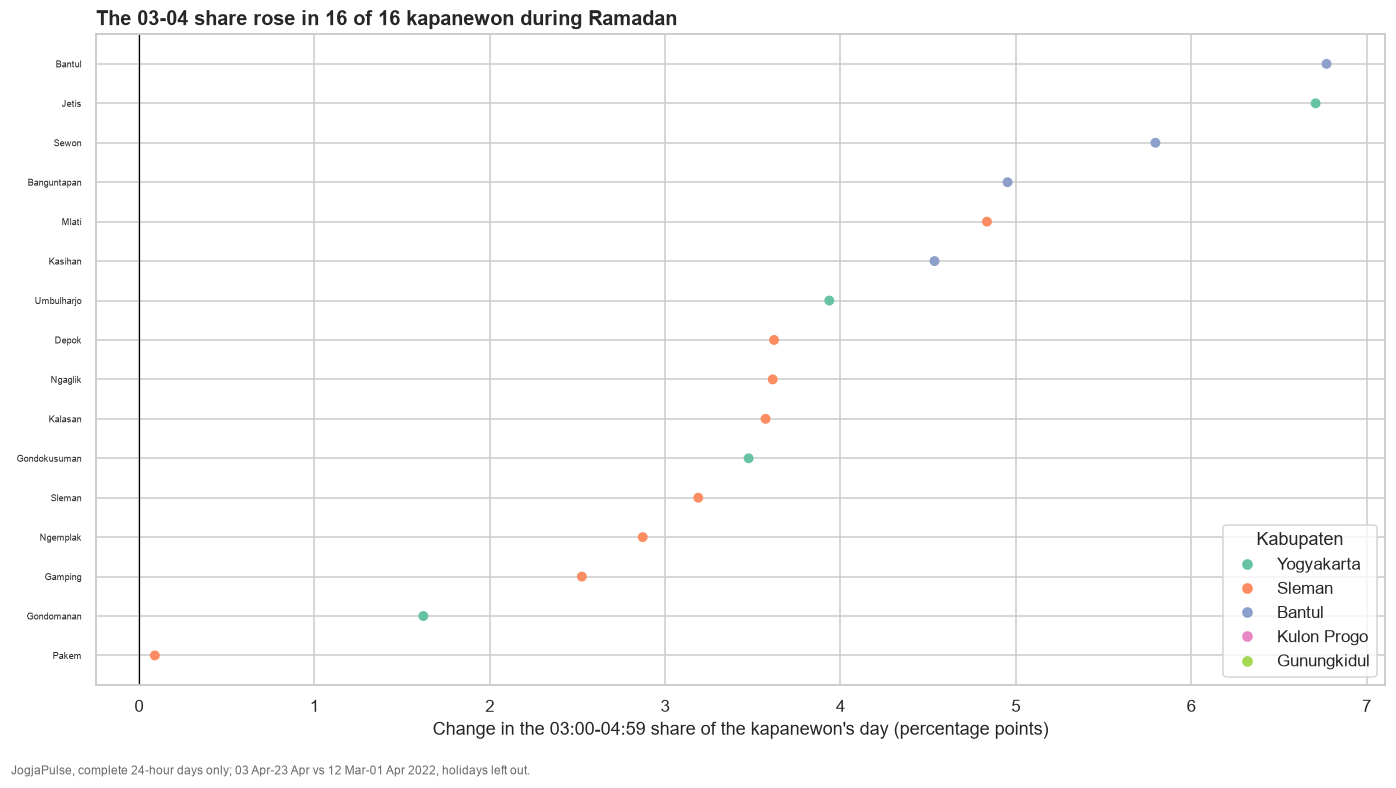

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE)
order = kap.sort_values("sahur 03-04 change (pp)").index
y = np.arange(len(order))
ax.scatter(kap.loc[order, "sahur 03-04 change (pp)"], y, c=[KAB_COL[k] for k in kap.loc[order, "kab_kota"]],
           s=30, zorder=3)
ax.axvline(0, color="black", lw=.8)
ax.set_yticks(y, [names.kapanewon[c].title() for c in order], fontsize=6)
handles = [plt.Line2D([], [], marker="o", ls="", color=KAB_COL[k]) for k in KAB_ORDER]
ax.legend(handles, [k.title() for k in KAB_ORDER], loc="lower right", title="Kabupaten")
ax.set_xlabel("Change in the 03:00-04:59 share of the kapanewon's day (percentage points)")
ax.set_title(f"The 03-04 share rose in {(kap['sahur 03-04 change (pp)'] > 0).sum()} of {len(kap)} kapanewon "
             "during Ramadan", loc="left")
fig.text(.01, .01, f"JogjaPulse, complete 24-hour days only; {during[0]:%d %b}-{during[-1]:%d %b} vs "
         f"{before[0]:%d %b}-{before[-1]:%d %b} 2022, holidays left out.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "sahur_by_kapanewon")

## 4. Where people go: Google categories, Ramadan 2022 and 2021

Mean Google value (% vs the Jan–Feb 2020 weekday baseline) in the 21 days before and the first 21 days of Ramadan, for both years. Weekends are kept in both windows, and each window has three of each weekday, so the weekday mix is the same. A change with the same sign in both years is more likely Ramadan than season.

Holidays left out: 2022 from the calendar file; 2021 has Good Friday on 2 Apr 2021 (Easter Sunday was 4 Apr 2021) in the window before. Other 2021 holidays are outside the windows.

In [7]:
g_all = pd.read_csv(RAW_EXT / "google_mobility" / "google_mobility_diy.csv", parse_dates=["date"])
g_all = g_all.set_index("date")
cols = [c for c in g_all.columns if any(c.startswith(k) for k in GOOGLE_CATEGORIES)]
g_all = g_all[cols].rename(columns=lambda c: next(k for k in GOOGLE_CATEGORIES if c.startswith(k)))
HOL_2021 = pd.to_datetime(["2021-04-02"])

rows = {}
for year, start, hol in [(2021, RAMADAN_2021_START, HOL_2021), (2022, START, daily.index[daily.is_holiday])]:
    b, d = ramadan_windows(start)
    b, d = b.difference(hol), d.difference(hol)
    assert g_all.reindex(b.union(d)).notna().all().all(), f"Google gaps in {year}"
    rows[year] = g_all.loc[d].mean() - g_all.loc[b].mean()
g_tbl = pd.DataFrame(rows).reindex(GOOGLE_CATEGORIES).round(1)
g_tbl["same sign"] = np.sign(g_tbl[2021]) == np.sign(g_tbl[2022])
print("Change in Google value, first 21 days of Ramadan minus the 21 days before (percentage points):")
display(g_tbl)

Change in Google value, first 21 days of Ramadan minus the 21 days before (percentage points):


,2021,2022,same sign
retail_and_recreation,-7.8,-8.8,True
grocery_and_pharmacy,-2.8,-5.0,True
parks,-19.3,-25.8,True
transit_stations,-7.9,-11.4,True
workplaces,-0.2,1.8,False
residential,4.2,2.2,True


In [8]:
jp_cols = {"jp_share_gunungkidul": "Gunungkidul share", "jp_city_daytime_share": "Kota Yogyakarta daytime share"}
jp_tbl = pd.DataFrame({"before": daily.loc[before, list(jp_cols)].mean(),
                       "Ramadan": daily.loc[during, list(jp_cols)].mean()}).rename(index=jp_cols) * 100
jp_tbl["change (%)"] = (jp_tbl.Ramadan / jp_tbl.before - 1) * 100
print("JogjaPulse shares in the same 2022 windows (% of DIY device-hours):")
display(jp_tbl.round(2))

JogjaPulse shares in the same 2022 windows (% of DIY device-hours):


,before,Ramadan,change (%)
Gunungkidul share,6.34,4.46,-29.55
Kota Yogyakarta daytime share,19.78,25.33,28.08


### 4b. Placebo: the same comparison 3 weeks earlier

The JogjaPulse panel drifts toward the city through S3 (notebook 01), and Google's categories drift with the season. If the change between two back-to-back 21-day windows is as large without Ramadan in them, the Ramadan change is not evidence of anything. The placebo shifts both windows 21 days earlier (2022: 20 Feb–11 Mar vs 13 Mar–2 Apr; still inside S3).

In [9]:
def change(start, hol, frame, cols, relative):
    b, d = ramadan_windows(start)
    b, d = b.difference(hol), d.difference(hol)
    lo, hi = frame.loc[b, cols].mean(), frame.loc[d, cols].mean()
    return (hi / lo - 1) * 100 if relative else hi - lo

SHIFT = pd.Timedelta(days=21)
hol22 = daily.index[daily.is_holiday]
assert (daily.panel_segment.reindex(pd.date_range(START - SHIFT - pd.Timedelta(days=22), START - pd.Timedelta(days=2)))
        == "S3 16 Feb-Apr").all()
plc = pd.DataFrame({
    "Ramadan 2022": pd.concat([change(START, hol22, daily, list(jp_cols), True).rename(jp_cols),
                               change(START, hol22, g_all, GOOGLE_CATEGORIES, False)]),
    "placebo 2022": pd.concat([change(START - SHIFT, hol22, daily, list(jp_cols), True).rename(jp_cols),
                               change(START - SHIFT, hol22, g_all, GOOGLE_CATEGORIES, False)]),
    "Ramadan 2021": change(RAMADAN_2021_START, HOL_2021, g_all, GOOGLE_CATEGORIES, False),
    "placebo 2021": change(RAMADAN_2021_START - SHIFT, HOL_2021, g_all, GOOGLE_CATEGORIES, False),
}).round(1)
print("JogjaPulse rows: % change of the share; Google rows: percentage points")
display(plc)

JogjaPulse rows: % change of the share; Google rows: percentage points


,Ramadan 2022,placebo 2022,Ramadan 2021,placebo 2021
Gunungkidul share,-29.5,3.2,NaN,NaN
Kota Yogyakarta daytime share,28.1,0.9,NaN,NaN
grocery_and_pharmacy,-5.0,1.3,-2.8,5.1
parks,-25.8,16.4,-19.3,5.4
residential,2.2,1.1,4.2,-1.7
retail_and_recreation,-8.8,5.2,-7.8,4.1
transit_stations,-11.4,9.3,-7.9,7.1
workplaces,1.8,9.7,-0.2,2.9


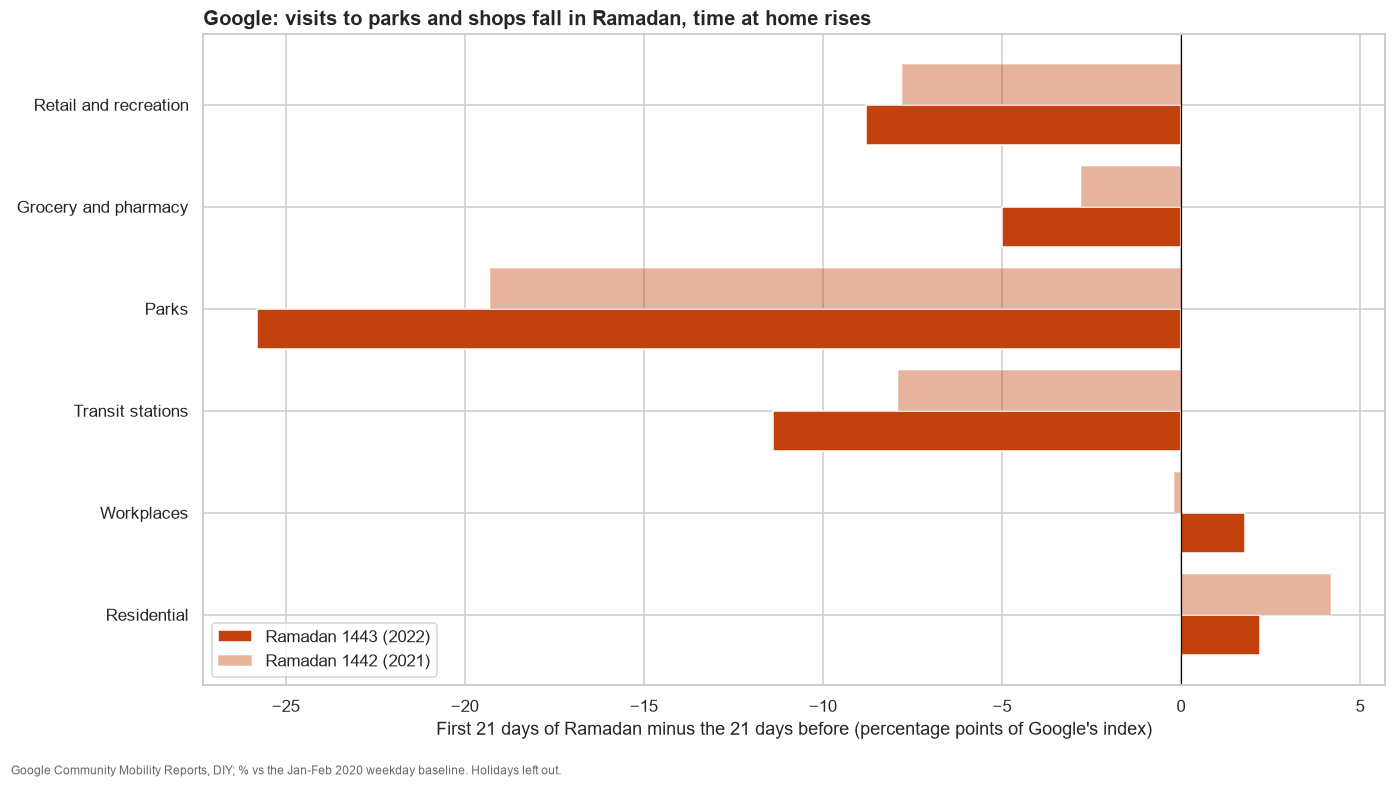

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE)
y = np.arange(len(GOOGLE_CATEGORIES))
ax.barh(y + .2, g_tbl[2022], height=.4, color=G_COL, label="Ramadan 1443 (2022)")
ax.barh(y - .2, g_tbl[2021], height=.4, color=G_COL, alpha=.4, label="Ramadan 1442 (2021)")
ax.set_yticks(y, [c.replace("_", " ").capitalize() for c in GOOGLE_CATEGORIES])
ax.invert_yaxis()
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("First 21 days of Ramadan minus the 21 days before (percentage points of Google's index)")
ax.legend(loc="lower left")
ax.set_title("Google: visits to parks and shops fall in Ramadan, time at home rises", loc="left")
fig.text(.01, .01, "Google Community Mobility Reports, DIY; % vs the Jan-Feb 2020 weekday baseline. "
         "Holidays left out.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "google_categories")

## 5. Summary numbers for the script

In [11]:
print(f"03-04 share: {block_tbl.loc['03-04', 'before (%)']:.1f}% before -> {block_tbl.loc['03-04', 'Ramadan (%)']:.1f}% "
      f"in Ramadan ({block_tbl.loc['03-04', 'change (pp)']:+.1f} pp); {n_above} of {len(during)} Ramadan days above the "
      f"highest day before")
print(f"00-02 share: {block_tbl.loc['00-02', 'before (%)']:.1f}% -> {block_tbl.loc['00-02', 'Ramadan (%)']:.1f}%")
print(f"Without the 4 kapanewon that drove 00-02: 03-04 {d_rest[[3, 4]].sum():+.2f} pp, 00-02 {d_rest[[0, 1, 2]].sum():+.2f} pp")
print(f"Kapanewon with a higher 03-04 share: {(kap['sahur 03-04 change (pp)'] > 0).sum()} of {len(kap)}")
for c in GOOGLE_CATEGORIES:
    print(f"Google {c}: 2022 {g_tbl.loc[c, 2022]:+.1f}, 2021 {g_tbl.loc[c, 2021]:+.1f}")
print(f"JP Gunungkidul share change: {jp_tbl.loc['Gunungkidul share', 'change (%)']:+.1f}%")

03-04 share: 3.7% before -> 8.1% in Ramadan (+4.3 pp); 19 of 20 Ramadan days above the highest day before
00-02 share: 11.3% -> 5.9%
Without the 4 kapanewon that drove 00-02: 03-04 +4.68 pp, 00-02 +0.47 pp
Kapanewon with a higher 03-04 share: 16 of 16
Google retail_and_recreation: 2022 -8.8, 2021 -7.8
Google grocery_and_pharmacy: 2022 -5.0, 2021 -2.8
Google parks: 2022 -25.8, 2021 -19.3
Google transit_stations: 2022 -11.4, 2021 -7.9
Google workplaces: 2022 +1.8, 2021 -0.2
Google residential: 2022 +2.2, 2021 +4.2
JP Gunungkidul share change: -29.5%


Interpretation (wording follows the numbers printed above):

- The clearest Ramadan signal in JogjaPulse is timing. The share of the day at 03:00-04:59 goes from 3.7% before Ramadan to 8.1% in the first three weeks, a jump that starts on 2-3 Apr. 19 of 20 Ramadan days are above the highest day before. It rose in all 16 kapanewon with enough complete days, and in every kabupaten. These are likely the sahur hours. The 03-04 share was already creeping up in late March, so part of the 4.3 pp may be drift, but the step at 2-3 Apr is far larger than that drift.
- The 00:00-02:59 share falls from 11.3% to 5.9%, but that is local: before Ramadan, Gondomanan alone held 44.6% of DIY 00-02 device-hours. Without the 4 kapanewon that drove it, the 00-02 share does not fall (+0.47 pp). What happened in Gondomanan after midnight before Ramadan is not known from this data.
- Google shows fewer visits to parks (-25.8 pp), transit (-11.4), retail (-8.8) and grocery (-5.0), and more time at home (+2.2), in the first three weeks of Ramadan 2022. Ramadan 2021 shows the same signs for these five categories. The placebo three weeks earlier moves the other way in both years, so the change is likely Ramadan, not the season.
- JogjaPulse agrees with Google on leisure: the Gunungkidul share falls 29.5% (placebo +3.2%), in the same direction as Google parks. That is the pair notebook 02 found to agree best, so Output 1 supports reading it here. The Kota Yogyakarta daytime share rises 28.1% (placebo +0.9%).
- Limitations: one Ramadan in JogjaPulse, no control region, devices are not people. Google is province-level. The data ends on 30 Apr, before Idul Fitri (2 May 2022), so mudik is not covered.